In [228]:
import matplotlib.pyplot as plt
import torch
import tqdm

%matplotlib inline

In [8]:
words = []
with open('names.txt', 'r') as f:
    words = f.read().splitlines()

chars = sorted(set(''.join(words)))
itos = {i+1:s for i, s in enumerate(chars)}
itos[0] = '.'

stoi = {s:i for i, s in itos.items()}



In [159]:
ctx_len = 3
Xtr, Ytr = [], []
Xval, Yval = [], []
Xtest, Ytest = [], []

def create_dataset(words):

    X, Y = [], []

    for w in words:
        context = [0] * ctx_len
        for c in w+'.':
            X.append(context)
            Y.append(stoi[c])
            context = context[1:] + [stoi[c]]

    return torch.tensor(X), torch.tensor(Y)


import random

random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = create_dataset(words[:n1])
Xval, Yval = create_dataset(words[n1:n2])
Xtest, Ytest = create_dataset(words[n2:])

In [237]:
# initial network structure
embedding_size = 15
hidden_layer_size = 300

C = torch.randn((27, embedding_size))
W1 = torch.randn((ctx_len * embedding_size, hidden_layer_size))
b1 = torch.randn(hidden_layer_size) 
W2 = torch.randn((hidden_layer_size, 27))
b2 = torch.randn(27)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

sum(p.nelement() for p in parameters)

22332

In [238]:
its = []
losses = []
lre = reversed(torch.linspace(-4, -1, 5))
lrs = 10**lre
lrs

tensor([1.0000e-01, 1.7783e-02, 3.1623e-03, 5.6234e-04, 1.0000e-04])

In [239]:
# training
for it in tqdm.tqdm(range(100000)):
    # create mini batch

    batch = torch.randint(0, Xtr.shape[0], (64, ))

    emb = C[Xtr[batch]]
    h = torch.tanh(emb.view(-1, ctx_len * embedding_size) @ W1 + b1)
    logits = h @ W2 + b2
    loss = torch.nn.functional.cross_entropy(logits, Ytr[batch])
    # print(loss.item())

    for p in parameters:
        p.grad = None

    loss.backward()

    lr = lrs[int(it / 20000)]
    for p in parameters:
        p.data += -lr * p.grad

    losses.append(loss.log10().item())
    its.append(it)

print(loss.item())

100%|██████████| 100000/100000 [00:18<00:00, 5532.87it/s]

2.4916765689849854


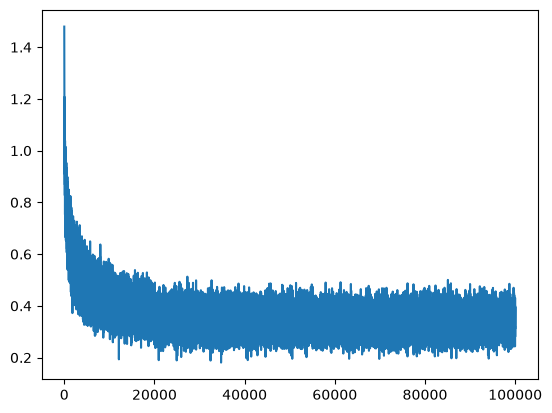

In [240]:
plt.plot(its, losses)

In [241]:
# calculate loss on validation set

def calc_loss(X, Y):
    emb = C[X].view(-1, ctx_len * embedding_size);
    h = torch.tanh(emb @ W1 + b1)
    logits = h @ W2 + b2
    loss = torch.nn.functional.cross_entropy(logits, Y)
    return loss

loss = calc_loss(Xval, Yval)
loss.item()

2.2490808963775635